# 02 · EMT-TF Expression — Bischoff 2021 LUAD

The expression step is **unconditional** — produced regardless of the gate outcome (§2), renumbered to
**02** because Gate 1 was NO-GO (§6: preprocessing 01 + expression 02). It reads `processed.h5ad` and
overlays the most informative EMT transcription factors on the malignant embedding.

Because Gate 1 was NO-GO, no trajectory exists to polarize the factors along; this panel is a descriptive
readout of which EMT-TFs are expressed in the LUAD malignant compartment, **detection-gated** (Kürten
lesson: score on detectable expression, widen beyond the canonical Snail/Zeb/Twist panel to FOXC/PRRX/SOX;
VIM excluded — mesenchymal marker, not a transcription factor).

In [1]:
import os, sys, re
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import warnings, logging; warnings.filterwarnings('ignore'); logging.disable(logging.INFO)
sc.settings.verbosity = 0

### Paths + load `processed.h5ad`

In [3]:
cwd = os.getcwd()
name = os.path.split(cwd)[1]
category = os.path.split(os.path.split(cwd)[0])[1]
pth = os.path.join('..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', category, name)
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
print(adata.shape, '| Gate 1 = NO-GO (two-lobe, not continuous); overlay is descriptive, no trajectory')

(13382, 24764) | Gate 1 = NO-GO (two-lobe, not continuous); overlay is descriptive, no trajectory


### Detection-gated EMT-TF panel
Score a broad candidate panel by fraction of malignant cells with non-zero expression; keep factors above
a 3% detection floor (10x dropout), show the top-4.

In [5]:
candidates = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2',
              'SOX4','SOX9','TCF3','TCF4','LEF1','TEAD1','ETS1','RUNX2','TBX3','NFATC2']
present = [g for g in candidates if g in adata.var_names]
X = adata[:, present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
det = (X>0).mean(0)
tab = pd.DataFrame({'gene':present,'detect_frac':det.round(3)}).sort_values('detect_frac',ascending=False).reset_index(drop=True)
FLOOR = 0.03
tab['pass'] = tab.detect_frac >= FLOOR
print(tab.to_string(index=False))
below = tab[~tab['pass']].gene.tolist()
panel = tab[tab['pass']].gene.tolist()[:4]
print(f'\nbelow {FLOOR:.0%} floor (excluded): {below}')
print(f'top detectable EMT-TFs shown: {panel}')

  gene  detect_frac  pass
  SOX4        0.831  True
  SOX9        0.443  True
 TEAD1        0.442  True
 FOXC1        0.330  True
  TCF3        0.244  True
  ETS1        0.154  True
 SNAI1        0.152  True
 RUNX2        0.138  True
 PRRX2        0.100  True
NFATC2        0.098  True
 PRRX1        0.055  True
  ZEB1        0.051  True
  ZEB2        0.044  True
  TCF4        0.038  True
  TBX3        0.033  True
TWIST2        0.024 False
 SNAI2        0.018 False
  LEF1        0.011 False
TWIST1        0.007 False
 FOXC2        0.003 False

below 3% floor (excluded): ['TWIST2', 'SNAI2', 'LEF1', 'TWIST1', 'FOXC2']
top detectable EMT-TFs shown: ['SOX4', 'SOX9', 'TEAD1', 'FOXC1']


### EMT-TF detection barplot

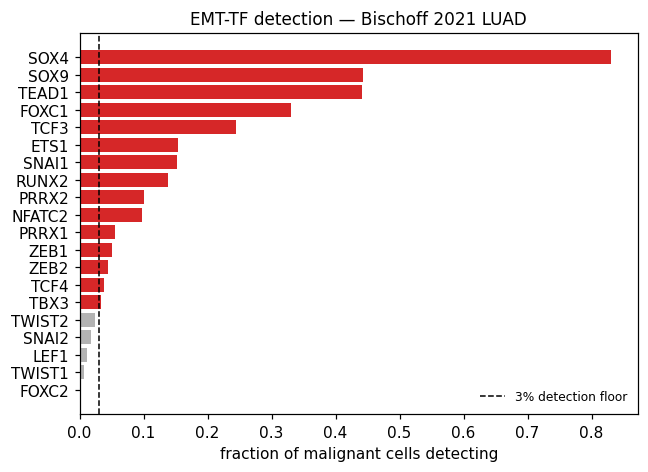

In [7]:
fig, ax = plt.subplots(figsize=(6,4.4))
colors = ['tab:red' if p else '0.7' for p in tab['pass']]
ax.barh(tab.gene[::-1], tab.detect_frac[::-1], color=colors[::-1])
ax.axvline(FLOOR, ls='--', color='k', lw=1, label=f'{FLOOR:.0%} detection floor')
ax.set_xlabel('fraction of malignant cells detecting'); ax.set_title('EMT-TF detection — Bischoff 2021 LUAD', size=11)
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); plt.show()

### EMT-TF expression on the embedding (top-4 detectable)

In [9]:
fig, axes = plt.subplots(1, len(panel), figsize=(4.6*len(panel), 4.4))
if len(panel)==1: axes=[axes]
detmap = tab.set_index('gene').detect_frac
for ax,g in zip(axes,panel):
    col = f'expr_{g}'
    xg = adata[:,g].X
    adata.obs[col] = np.asarray(xg.todense()).ravel() if hasattr(xg,'todense') else np.asarray(xg).ravel()
    vmax = np.percentile(adata.obs[col][adata.obs[col]>0], 98) if (adata.obs[col]>0).any() else 1.0
    sc.pl.umap(adata, color=col, ax=ax, show=False, size=18, frameon=False,
               title=f'{g}  ({detmap[g]:.0%} detect)', cmap='viridis', vmax=vmax)
fig.suptitle('EMT-TF expression — top detectable factors (SOX4/SOX9/TEAD1/FOXC1; canonical Snail/Twist below floor)', size=11)
fig.tight_layout()
fn = os.path.join(pth_fig, 'expression.pdf')
fig.savefig(fn, bbox_inches='tight'); print('saved expression.pdf | panel:', panel)

saved expression.pdf | panel: ['SOX4', 'SOX9', 'TEAD1', 'FOXC1']
